**Energy Consumption Prediction**:
This project uses Machine Learning to predict energy consumption by analyzing energy-related data. It involves data preprocessing, exploratory data analysis, and training three regression models: Linear Regression, Decision Tree, and Random Forest. The models are evaluated using MAE, MSE, RMSE, and R² score to compare their performance and identify the most suitable model for energy consumption prediction.

In [1]:

# STEP 1: DATA LOADING AND INITIAL INSPECTION

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())


Saving Energy_consumption.csv to Energy_consumption.csv
Dataset loaded successfully!

Dataset shape: (1000, 11)

Column names:
['Timestamp', 'Temperature', 'Humidity', 'SquareFootage', 'Occupancy', 'HVACUsage', 'LightingUsage', 'RenewableEnergy', 'DayOfWeek', 'Holiday', 'EnergyConsumption']

First five rows:


,Timestamp,Temperature,Humidity,SquareFootage,Occupancy,HVACUsage,LightingUsage,RenewableEnergy,DayOfWeek,Holiday,EnergyConsumption
0,2022-01-01 00:00:00,25.139433,43.431581,1565.693999,5,On,Off,2.774699,Monday,No,75.364373
1,2022-01-01 01:00:00,27.731651,54.225919,1411.064918,1,On,On,21.831384,Saturday,No,83.401855
2,2022-01-01 02:00:00,28.704277,58.907658,1755.715009,2,Off,Off,6.764672,Sunday,No,78.270888
3,2022-01-01 03:00:00,20.080469,50.371637,1452.316318,1,Off,On,8.623447,Wednesday,No,56.519850
4,2022-01-01 04:00:00,23.097359,51.401421,1094.130359,9,On,Off,3.071969,Friday,No,70.811732



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Timestamp          1000 non-null   object 
 1   Temperature        1000 non-null   float64
 2   Humidity           1000 non-null   float64
 3   SquareFootage      1000 non-null   float64
 4   Occupancy          1000 non-null   int64  
 5   HVACUsage          1000 non-null   object 
 6   LightingUsage      1000 non-null   object 
 7   RenewableEnergy    1000 non-null   float64
 8   DayOfWeek          1000 non-null   object 
 9   Holiday            1000 non-null   object 
 10  EnergyConsumption  1000 non-null   float64
dtypes: float64(5), int64(1), object(5)
memory usage: 86.1+ KB

Missing values:
Timestamp            0
Temperature          0
Humidity             0
SquareFootage        0
Occupancy            0
HVACUsage            0
LightingUsage        0
Renewab

Shape before cleaning: (1000, 11)
Shape after cleaning: (1000, 11)

Missing values:
Timestamp            0
Temperature          0
Humidity             0
SquareFootage        0
Occupancy            0
HVACUsage            0
LightingUsage        0
RenewableEnergy      0
DayOfWeek            0
Holiday              0
EnergyConsumption    0
dtype: int64

Missing values after cleaning:
Timestamp            0
Temperature          0
Humidity             0
SquareFootage        0
Occupancy            0
HVACUsage            0
LightingUsage        0
RenewableEnergy      0
DayOfWeek            0
Holiday              0
EnergyConsumption    0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Timestamp          1000 non-null   object 
 1   Temperature        1000 non-null   float64
 2   Humidity           1000 non

,Timestamp,Temperature,Humidity,SquareFootage,Occupancy,HVACUsage,LightingUsage,RenewableEnergy,DayOfWeek,Holiday,EnergyConsumption
count,1000,1000.000000,1000.000000,1000.000000,1000.000000,1000,1000,1000.000000,1000,1000,1000.000000
unique,1000,NaN,NaN,NaN,NaN,2,2,NaN,7,2,NaN
top,2022-02-11 15:00:00,NaN,NaN,NaN,NaN,Off,Off,NaN,Friday,No,NaN
freq,1,NaN,NaN,NaN,NaN,508,509,NaN,164,533,NaN
mean,NaN,24.982026,45.395412,1500.052488,4.581000,NaN,NaN,15.132813,NaN,NaN,77.055873
std,NaN,2.836850,8.518905,288.418873,2.865598,NaN,NaN,8.745917,NaN,NaN,8.144112
min,NaN,20.007565,30.015975,1000.512661,0.000000,NaN,NaN,0.006642,NaN,NaN,53.263278
25%,NaN,22.645070,38.297722,1247.108548,2.000000,NaN,NaN,7.628385,NaN,NaN,71.544690
50%,NaN,24.751637,45.972116,1507.967426,5.000000,NaN,NaN,15.072296,NaN,NaN,76.943696
75%,NaN,27.418174,52.420066,1740.340165,7.000000,NaN,NaN,22.884064,NaN,NaN,82.921742


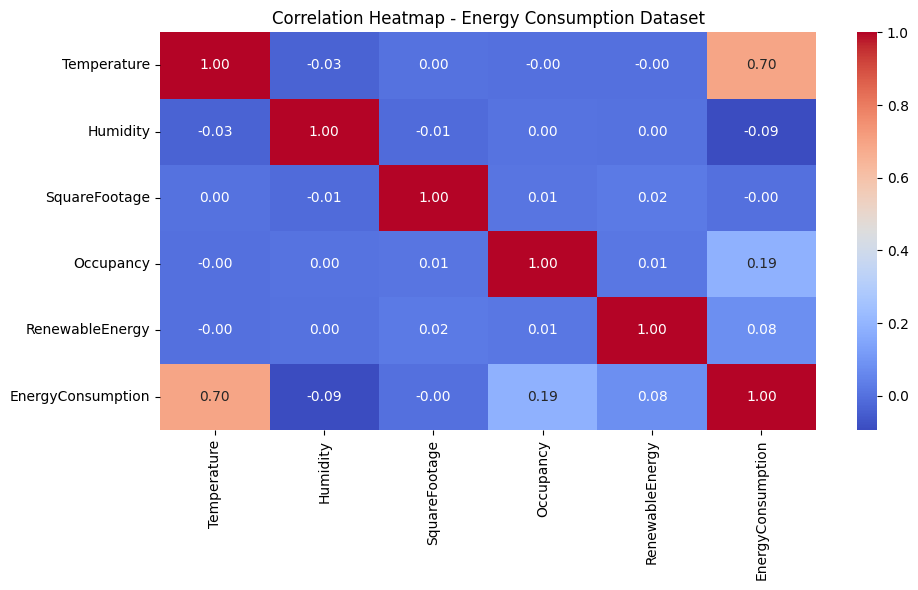

In [4]:
# STEP 2: DATA CLEANING AND INITIAL ANALYSIS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Check dataset shape
print("Shape before cleaning:", df.shape)

# 2. Remove duplicate rows
df = df.drop_duplicates()
print("Shape after cleaning:", df.shape)

# 3. Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# 4. Handle missing numerical values
numeric_cols = df.select_dtypes(include=["number"]).columns
for col in numeric_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

# 5. Handle missing categorical values
categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns
for col in categorical_cols:
    if df[col].isnull().any():
        mode_values = df[col].mode()
        if len(mode_values) > 0:
            df[col] = df[col].fillna(mode_values.iloc[0])

# 6. Verify missing values after cleaning
print("\nMissing values after cleaning:")
print(df.isnull().sum())

# 7. Display dataset information
print("\nDataset information:")
df.info()

# 8. Display statistical summary
print("\nStatistical summary:")
display(df.describe(include="all"))

# 9. Correlation heatmap
numeric_df = df.select_dtypes(include=["number"])
if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(10, 6))
    sns.heatmap(
        numeric_df.corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )
    plt.title("Correlation Heatmap - Energy Consumption Dataset")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numerical columns for a correlation heatmap.")

Available columns:
['Timestamp', 'Temperature', 'Humidity', 'SquareFootage', 'Occupancy', 'HVACUsage', 'LightingUsage', 'RenewableEnergy', 'DayOfWeek', 'Holiday', 'EnergyConsumption']


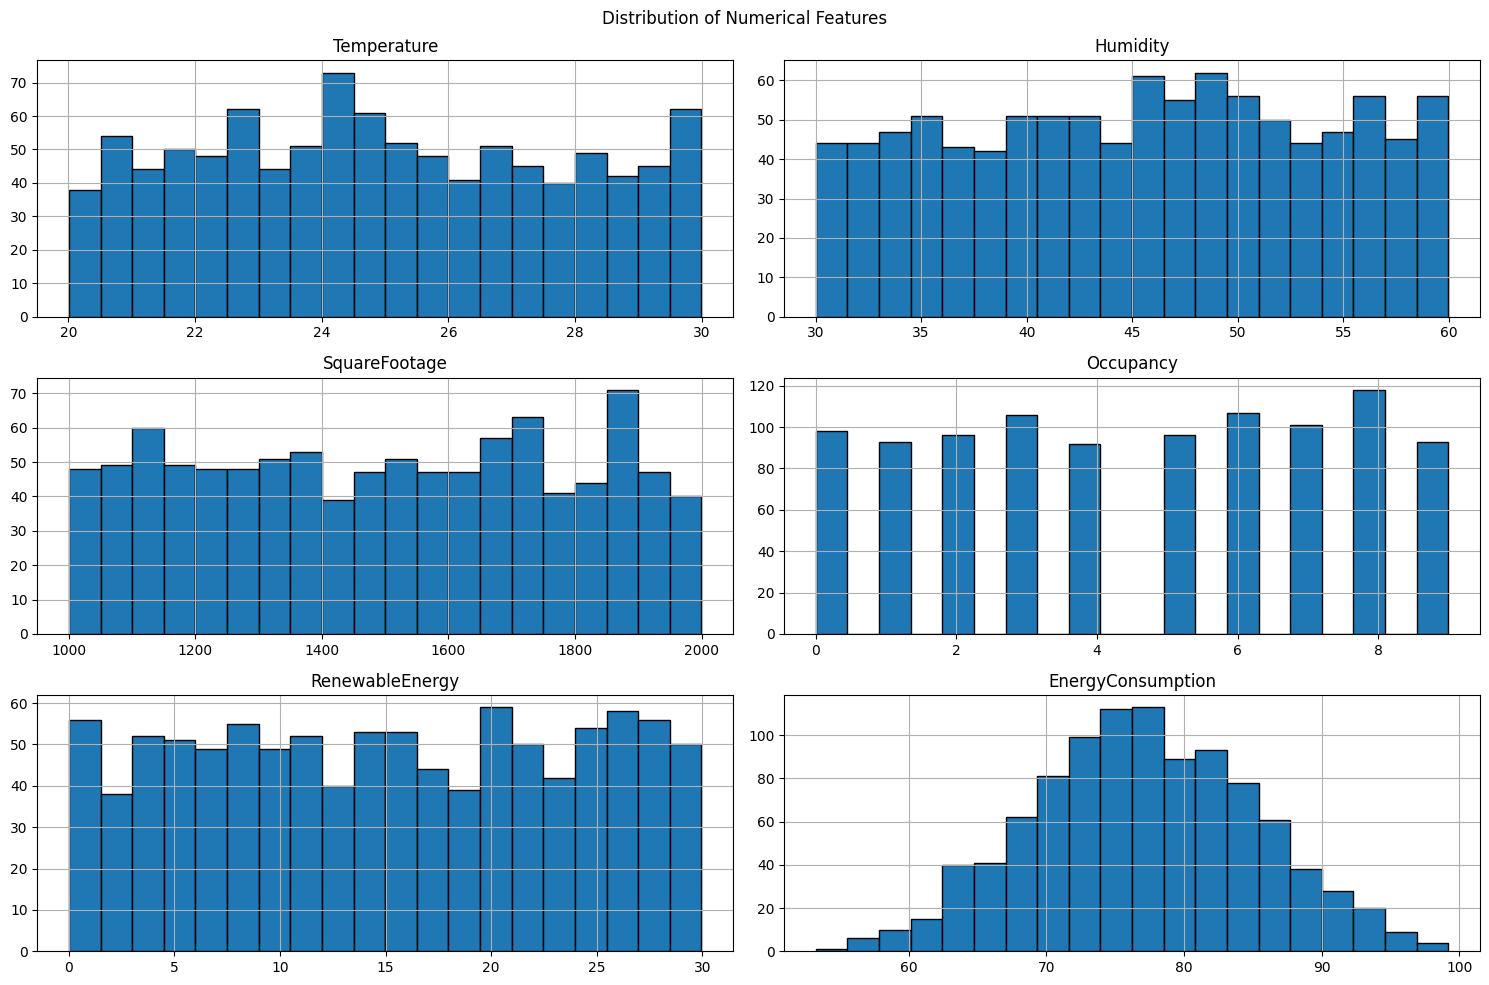

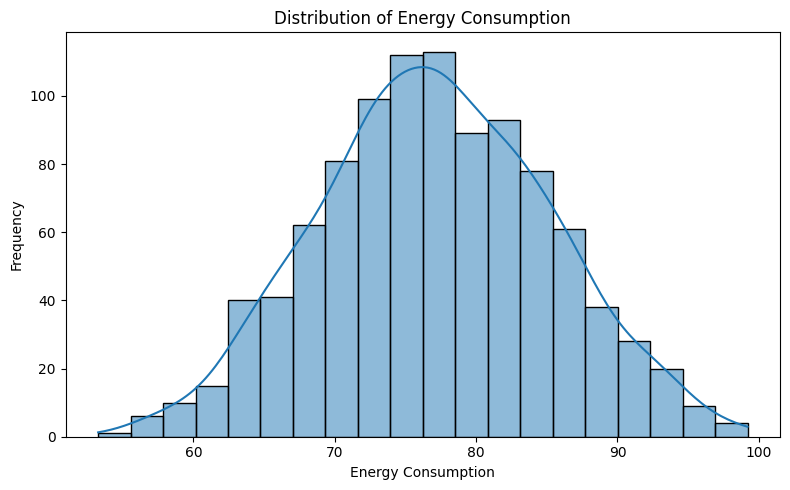

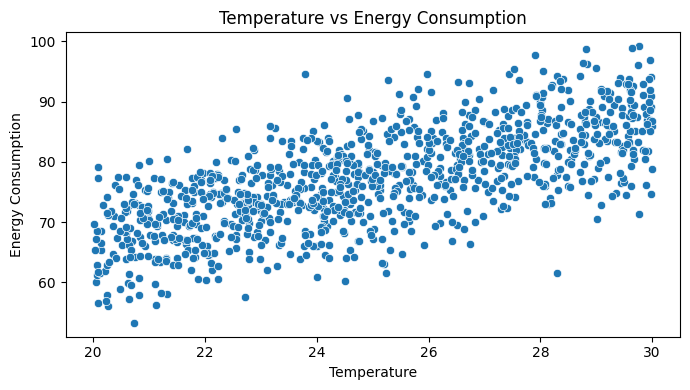

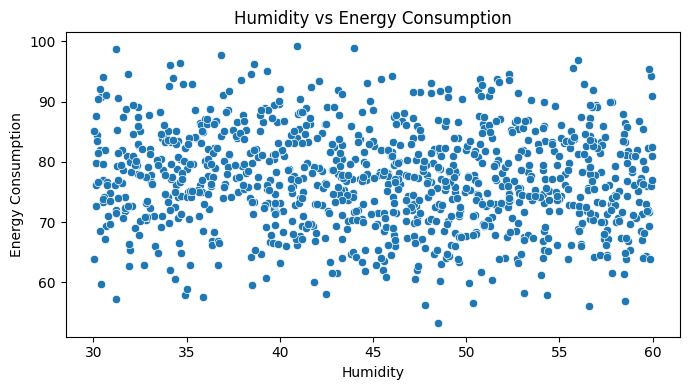

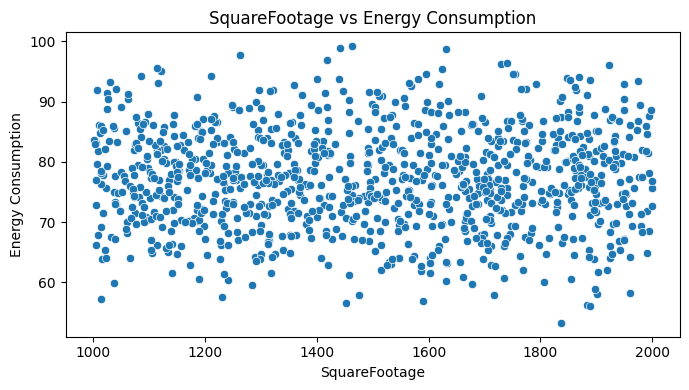

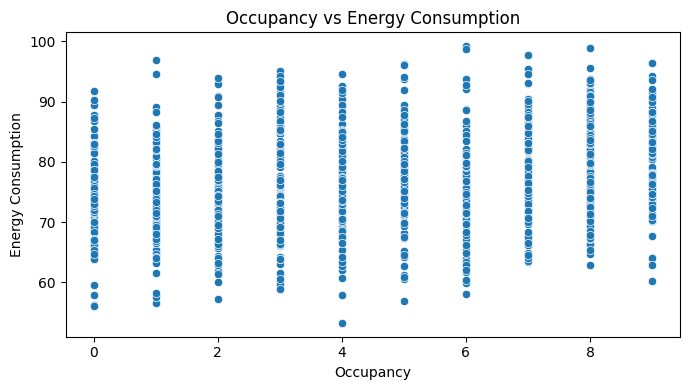

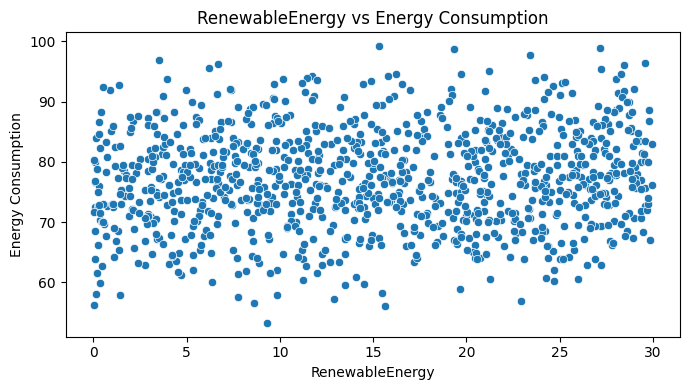

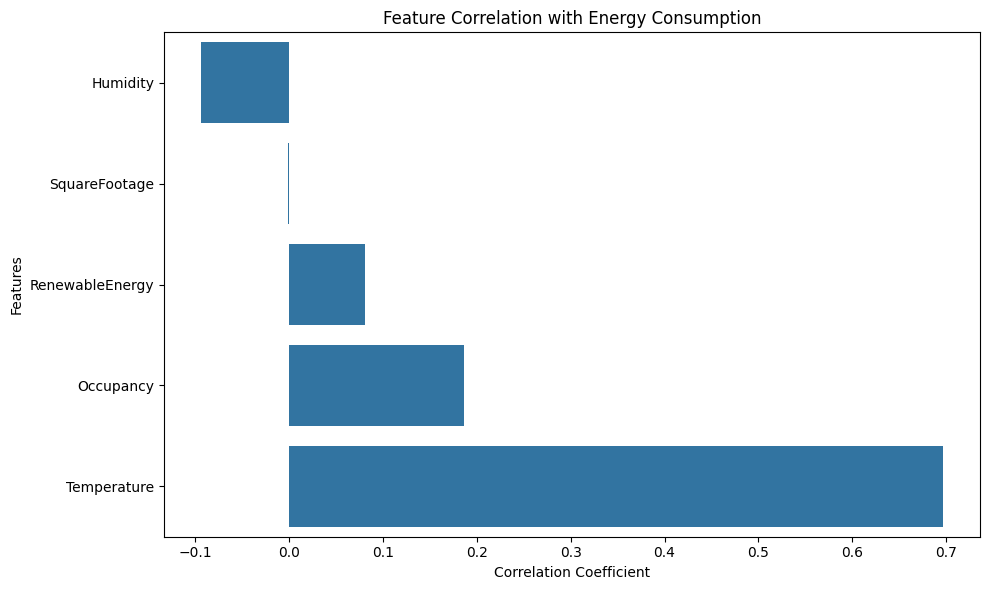

In [6]:
# STEP 3: EXPLORATORY DATA VISUALIZATION

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# 1. Display dataset columns
print("Available columns:")
print(df.columns.tolist())

# 2. Plot numerical feature distributions
numeric_cols = df.select_dtypes(include=["number"]).columns

df[numeric_cols].hist(
    figsize=(15, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

# 3. Plot energy consumption distribution
target_col = "EnergyConsumption"

if target_col in df.columns:
    plt.figure(figsize=(8, 5))
    sns.histplot(
        data=df,
        x=target_col,
        bins=20,
        kde=True
    )
    plt.title("Distribution of Energy Consumption")
    plt.xlabel("Energy Consumption")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()
else:
    print("EnergyConsumption column not found.")

# 4. Plot energy consumption against numerical features
if target_col in df.columns:
    feature_cols = [col for col in numeric_cols if col != target_col]
    for col in feature_cols:
        plt.figure(figsize=(7, 4))
        sns.scatterplot(
            data=df,
            x=col,
            y=target_col
        )
        plt.title(f"{col} vs Energy Consumption")
        plt.xlabel(col)
        plt.ylabel("Energy Consumption")
        plt.tight_layout()
        plt.show()

# 5. Plot correlation with energy consumption
if target_col in numeric_cols:
    correlations = df[numeric_cols].corr()[target_col]
    correlations = correlations.drop(labels=[target_col])
    correlations = correlations.sort_values()

    plt.figure(figsize=(10, 6))
    sns.barplot(
        x=correlations.values,
        y=correlations.index
    )
    plt.title("Feature Correlation with Energy Consumption")
    plt.xlabel("Correlation Coefficient")
    plt.ylabel("Features")
    plt.tight_layout()
    plt.show()
else:
    print("Target column is not numerical or was not found.")

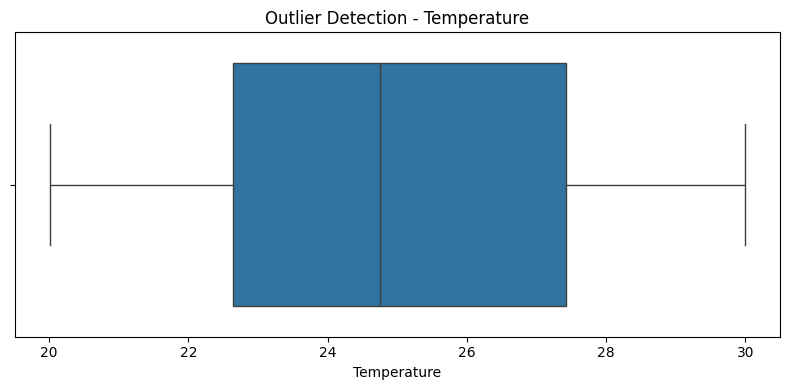

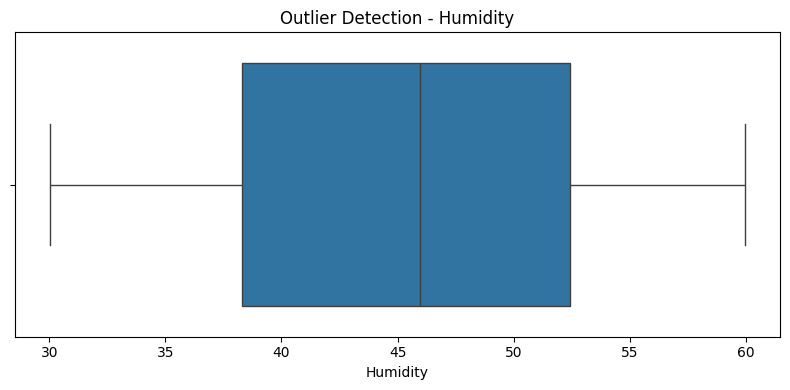

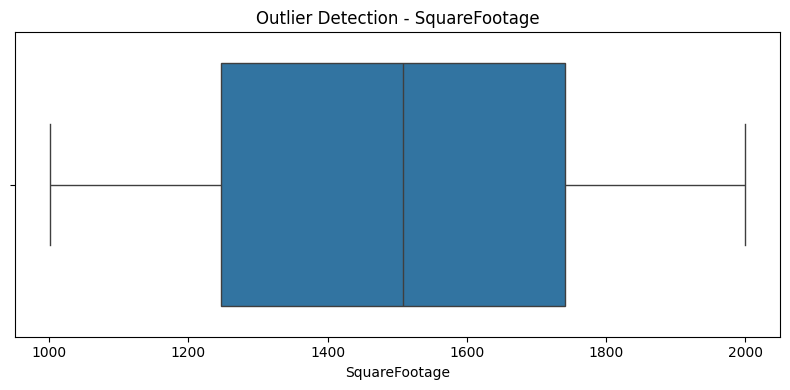

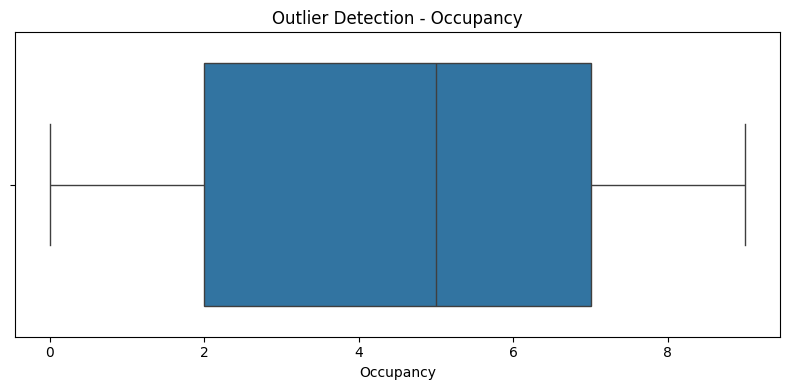

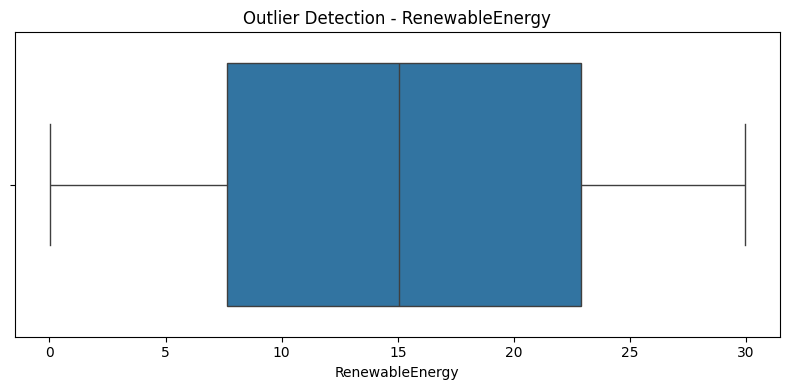

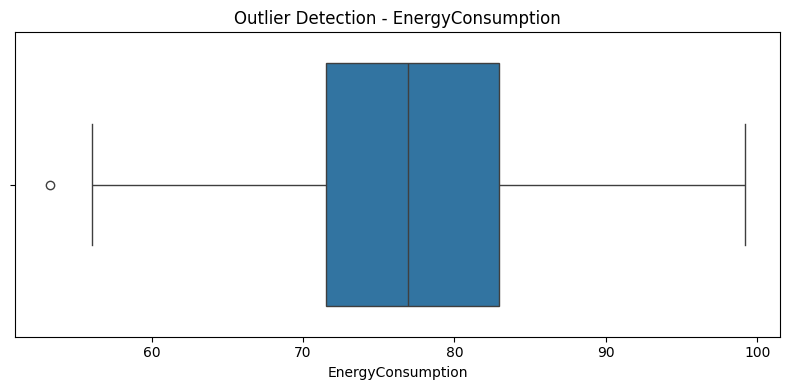

OUTLIER SUMMARY

Column: Temperature
Lower bound: 15.485
Upper bound: 34.578
Number of outliers: 0

Column: Humidity
Lower bound: 17.114
Upper bound: 73.604
Number of outliers: 0

Column: SquareFootage
Lower bound: 507.261
Upper bound: 2480.188
Number of outliers: 0

Column: Occupancy
Lower bound: -5.5
Upper bound: 14.5
Number of outliers: 0

Column: RenewableEnergy
Lower bound: -15.255
Upper bound: 45.768
Number of outliers: 0

Column: EnergyConsumption
Lower bound: 54.479
Upper bound: 99.987
Number of outliers: 1

Dataset shape: (1000, 11)


In [8]:
# STEP 4: OUTLIER DETECTION AND ANALYSIS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Select numerical columns
numeric_cols = df.select_dtypes(include=["number"]).columns

# 2. Plot boxplots for all numerical features
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title("Outlier Detection - " + col)
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

# 3. Detect outliers using the IQR method
print("OUTLIER SUMMARY")

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) | (df[col] > upper_bound)
    ]

    print("\nColumn:", col)
    print("Lower bound:", round(lower_bound, 3))
    print("Upper bound:", round(upper_bound, 3))
    print("Number of outliers:", len(outliers))

# 4. Display the dataset size
print("\nDataset shape:", df.shape)

In [10]:
# STEP 5: FEATURE SELECTION AND TARGET IDENTIFICATION

import pandas as pd
import numpy as np

# 1. Display all available columns
print("Available columns:")
print(df.columns.tolist())

# 2. Identify the target column
target_col = "EnergyConsumption"

if target_col not in df.columns:
    print("\nERROR: Target column not found.")
    print("Check the column names above and update target_col.")
else:
    # 3. Separate input features and target
    X = df.drop(columns=[target_col])
    y = df[target_col]

    # 4. Display input features
    print("\nInput feature columns:")
    print(X.columns.tolist())

    # 5. Display target information
    print("\nTarget variable:", target_col)
    print("Target data type:", y.dtype)

    # 6. Display shapes
    print("\nInput features shape:", X.shape)
    print("Target shape:", y.shape)

    # 7. Check numerical and categorical features
    numeric_features = X.select_dtypes(
        include=["number"]
    ).columns.tolist()

    categorical_features = X.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()

    print("\nNumerical features:")
    print(numeric_features)

    print("\nCategorical features:")
    print(categorical_features)

    # 8. Display target statistics
    print("\nTarget variable statistics:")
    print(y.describe())

Available columns:
['Timestamp', 'Temperature', 'Humidity', 'SquareFootage', 'Occupancy', 'HVACUsage', 'LightingUsage', 'RenewableEnergy', 'DayOfWeek', 'Holiday', 'EnergyConsumption']

Input feature columns:
['Timestamp', 'Temperature', 'Humidity', 'SquareFootage', 'Occupancy', 'HVACUsage', 'LightingUsage', 'RenewableEnergy', 'DayOfWeek', 'Holiday']

Target variable: EnergyConsumption
Target data type: float64

Input features shape: (1000, 10)
Target shape: (1000,)

Numerical features:
['Temperature', 'Humidity', 'SquareFootage', 'Occupancy', 'RenewableEnergy']

Categorical features:
['Timestamp', 'HVACUsage', 'LightingUsage', 'DayOfWeek', 'Holiday']

Target variable statistics:
count    1000.000000
mean       77.055873
std         8.144112
min        53.263278
25%        71.544690
50%        76.943696
75%        82.921742
max        99.201120
Name: EnergyConsumption, dtype: float64


In [12]:
# STEP 6: DATA PREPROCESSING AND FEATURE ENGINEERING

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# 1. Define the target variable
target_col = "EnergyConsumption"

if target_col not in df.columns:
    raise ValueError(
        "Target column not found. Check df.columns and update target_col."
    )

# 2. Separate input features and target
X = df.drop(columns=[target_col]).copy()
y = df[target_col].copy()

# 3. Remove rows where the target is missing
valid_rows = y.notna()
X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

# 4. Identify numerical and categorical columns
numeric_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numeric_cols)
print("Categorical features:", categorical_cols)

# 5. Split data before fitting preprocessing steps
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# 6. Impute missing numerical values
if numeric_cols:
    numeric_imputer = SimpleImputer(strategy="median")

    X_train_num = pd.DataFrame(
        numeric_imputer.fit_transform(X_train[numeric_cols]),
        columns=numeric_cols,
        index=X_train.index
    )

    X_test_num = pd.DataFrame(
        numeric_imputer.transform(X_test[numeric_cols]),
        columns=numeric_cols,
        index=X_test.index
    )
else:
    X_train_num = pd.DataFrame(index=X_train.index)
    X_test_num = pd.DataFrame(index=X_test.index)

# 7. Impute missing categorical values and encode them
if categorical_cols:
    categorical_imputer = SimpleImputer(strategy="most_frequent")

    X_train_cat = pd.DataFrame(
        categorical_imputer.fit_transform(X_train[categorical_cols]),
        columns=categorical_cols,
        index=X_train.index
    )

    X_test_cat = pd.DataFrame(
        categorical_imputer.transform(X_test[categorical_cols]),
        columns=categorical_cols,
        index=X_test.index
    )

    X_train_cat = pd.get_dummies(
        X_train_cat,
        drop_first=True,
        dtype=int
    )

    X_test_cat = pd.get_dummies(
        X_test_cat,
        drop_first=True,
        dtype=int
    )

    X_train_cat, X_test_cat = X_train_cat.align(
        X_test_cat,
        join="left",
        axis=1,
        fill_value=0
    )
else:
    X_train_cat = pd.DataFrame(index=X_train.index)
    X_test_cat = pd.DataFrame(index=X_test.index)

# 8. Combine numerical and categorical features
X_train_processed = pd.concat(
    [X_train_num, X_train_cat],
    axis=1
)

X_test_processed = pd.concat(
    [X_test_num, X_test_cat],
    axis=1
)

# 9. Scale numerical features using training data only
if numeric_cols:
    scaler = StandardScaler()

    X_train_processed[numeric_cols] = scaler.fit_transform(
        X_train_processed[numeric_cols]
    )

    X_test_processed[numeric_cols] = scaler.transform(
        X_test_processed[numeric_cols]
    )

# 10. Display final results
print("\nPreprocessing completed successfully!")

print("Training features shape:", X_train_processed.shape)
print("Testing features shape:", X_test_processed.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nMissing values in training features:",
      X_train_processed.isnull().sum().sum())

print("Missing values in testing features:",
      X_test_processed.isnull().sum().sum())

display(X_train_processed.head())

Numerical features: ['Temperature', 'Humidity', 'SquareFootage', 'Occupancy', 'RenewableEnergy']
Categorical features: ['Timestamp', 'HVACUsage', 'LightingUsage', 'DayOfWeek', 'Holiday']

Preprocessing completed successfully!
Training features shape: (800, 813)
Testing features shape: (200, 813)
Training target shape: (800,)
Testing target shape: (200,)

Missing values in training features: 0
Missing values in testing features: 0


,Temperature,Humidity,SquareFootage,Occupancy,RenewableEnergy,Timestamp_2022-01-01 01:00:00,Timestamp_2022-01-01 02:00:00,Timestamp_2022-01-01 03:00:00,Timestamp_2022-01-01 04:00:00,Timestamp_2022-01-01 05:00:00,...,Timestamp_2022-02-11 15:00:00,HVACUsage_On,LightingUsage_On,DayOfWeek_Monday,DayOfWeek_Saturday,DayOfWeek_Sunday,DayOfWeek_Thursday,DayOfWeek_Tuesday,DayOfWeek_Wednesday,Holiday_Yes
29,-0.600071,0.117232,0.510639,-0.930968,0.334790,0,0,0,0,0,...,0,0,1,0,0,0,0,1,0,0
535,-1.014074,-1.368855,1.711243,0.818150,-1.234490,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
695,0.415776,-0.242279,0.255739,-0.930968,-1.146918,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
557,-0.492925,-0.046732,-1.280685,0.468326,-0.883028,0,0,0,0,0,...,0,1,1,1,0,0,0,0,0,0
836,0.626245,-1.507695,0.812203,0.118503,0.797475,0,0,0,0,0,...,0,0,1,0,1,0,0,0,0,1


In [15]:
# STEP 7: MACHINE LEARNING MODEL BUILDING

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# 1. Initialize the machine learning models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

# 2. Train each model
trained_models = {}

for model_name, model in models.items():
    model.fit(X_train_processed, y_train)
    trained_models[model_name] = model
    print(f"{model_name} trained successfully!")

# 3. Display the training summary
print("\nMODEL BUILDING COMPLETED")
print("-" * 35)

print("Number of models trained:", len(trained_models))
print("Training records:", len(X_train_processed))
print("Testing records:", len(X_test_processed))
print("Number of input features:", X_train_processed.shape[1])

print("\nModels ready for evaluation:")
for model_name in trained_models:
    print("-", model_name)

Linear Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!

MODEL BUILDING COMPLETED
-----------------------------------
Number of models trained: 3
Training records: 800
Testing records: 200
Number of input features: 813

Models ready for evaluation:
- Linear Regression
- Decision Tree
- Random Forest


In [16]:
# STEP 8: MODEL EVALUATION

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd

# 1. Initialize empty lists to store metric results
evaluation_results = []

# 2. Iterate through each trained model and predict on test data
for name, model in trained_models.items():
    predictions = model.predict(X_test_processed)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    evaluation_results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

# 3. Present the metrics in a structured DataFrame
results_df = pd.DataFrame(evaluation_results)
display(results_df.sort_values(by="R2 Score", ascending=False))

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,4.213605,27.073858,5.203255,0.586658
2,Random Forest,4.251570,28.580540,5.346077,0.563655
1,Decision Tree,5.152309,46.124200,6.791480,0.295812


FEATURE IMPORTANCE RANKING


,Feature,Importance
0,Temperature,0.5576
804,HVACUsage_On,0.0705
4,RenewableEnergy,0.0595
3,Occupancy,0.0571
2,SquareFootage,0.0511
...,...,...
710,Timestamp_2022-02-06 16:00:00,0.0000
528,Timestamp_2022-01-28 07:00:00,0.0000
730,Timestamp_2022-02-07 19:00:00,0.0000
384,Timestamp_2022-01-20 15:00:00,0.0000


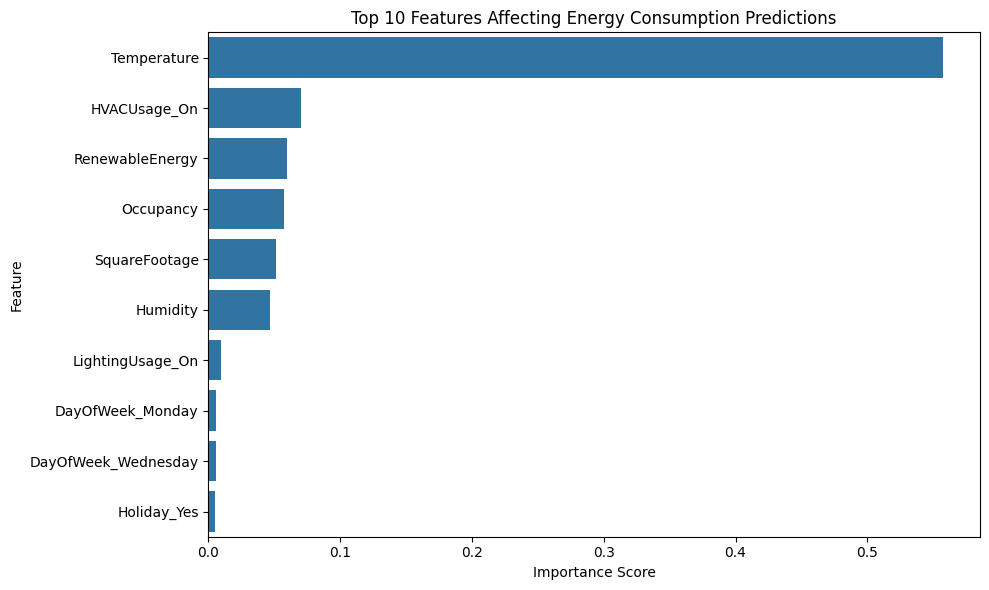


Most important feature: Temperature
Importance score: 0.5576


In [18]:
# STEP 9: FEATURE IMPORTANCE ANALYSIS

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Get the trained Random Forest model
rf_model = trained_models["Random Forest"]

# 2. Extract feature importance scores
feature_importance = pd.DataFrame({
    "Feature": X_train_processed.columns,
    "Importance": rf_model.feature_importances_
})

# 3. Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# 4. Display feature importance scores
print("FEATURE IMPORTANCE RANKING")
print("=" * 40)
display(feature_importance.round(4))

# 5. Plot the top 10 important features
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)
plt.title("Top 10 Features Affecting Energy Consumption Predictions")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# 6. Display the most important feature
if not feature_importance.empty:
    most_important = feature_importance.iloc[0]
    print("\nMost important feature:", most_important["Feature"])
    print("Importance score:", round(most_important["Importance"], 4))

FINAL MODEL COMPARISON


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,4.2136,27.0739,5.2033,0.5867
2,Random Forest,4.2516,28.5805,5.3461,0.5637
1,Decision Tree,5.1523,46.1242,6.7915,0.2958



BEST-PERFORMING MODEL
------------------------------
Model: Linear Regression
MAE: 4.2136
RMSE: 5.2033
R2 Score: 0.5867

TOP FIVE IMPORTANT FEATURES
------------------------------


,Feature,Importance
0,Temperature,0.5576
804,HVACUsage_On,0.0705
4,RenewableEnergy,0.0595
3,Occupancy,0.0571
2,SquareFootage,0.0511


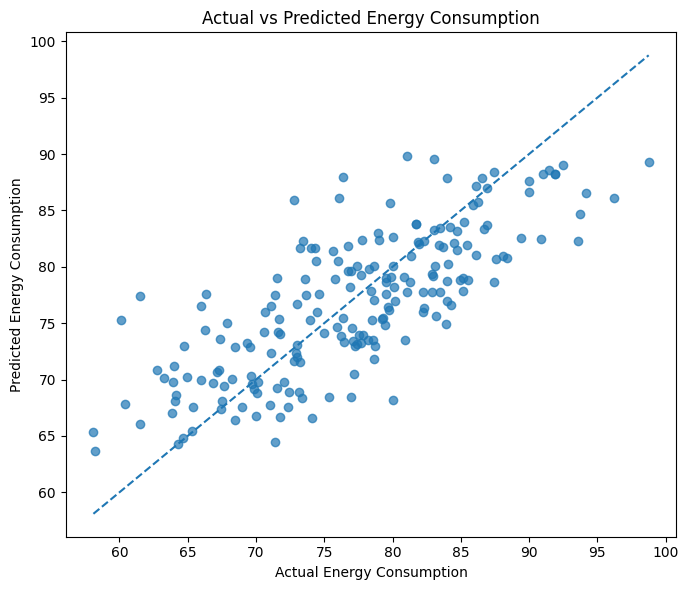


PROJECT CONCLUSION
Three regression models were trained and evaluated to predict energy consumption.
The model with the lowest RMSE was: Linear Regression
Its R2 score was 0.5867 which indicates the proportion of target variation explained by the model on the test set.
Feature importance results can help identify which input variables are most useful for prediction.

Note: Conclusions should be based on the displayed metrics and actual dataset features.


In [20]:
# STEP 10: FINAL RESULTS AND CONCLUSION

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Display model comparison
print("FINAL MODEL COMPARISON")
print("=" * 50)

display(
    results_df.sort_values(
        by="RMSE",
        ascending=True
    ).round(4)
)

# 2. Identify the best model based on RMSE
best_index = results_df["RMSE"].idxmin()
best_model_name = results_df.loc[best_index, "Model"]
best_rmse = results_df.loc[best_index, "RMSE"]
best_mae = results_df.loc[best_index, "MAE"]
best_r2 = results_df.loc[best_index, "R2 Score"]

print("\nBEST-PERFORMING MODEL")
print("-" * 30)
print("Model:", best_model_name)
print("MAE:", round(best_mae, 4))
print("RMSE:", round(best_rmse, 4))
print("R2 Score:", round(best_r2, 4))

# 3. Display the top five important features
print("\nTOP FIVE IMPORTANT FEATURES")
print("-" * 30)

display(feature_importance.head(5).round(4))

# 4. Plot actual vs predicted values for the best model
best_model = trained_models[best_model_name]
best_predictions = best_model.predict(X_test_processed)

plt.figure(figsize=(7, 6))
plt.scatter(
    y_test,
    best_predictions,
    alpha=0.7
)

# Reference line for perfect predictions
actual_min = min(y_test.min(), best_predictions.min())
actual_max = max(y_test.max(), best_predictions.max())
plt.plot(
    [actual_min, actual_max],
    [actual_min, actual_max],
    linestyle="--"
)

plt.title("Actual vs Predicted Energy Consumption")
plt.xlabel("Actual Energy Consumption")
plt.ylabel("Predicted Energy Consumption")
plt.tight_layout()
plt.show()

# 5. Print a conclusion based on the actual results
print("\nPROJECT CONCLUSION")
print("=" * 50)

print(
    "Three regression models were trained and evaluated "
    "to predict energy consumption."
)

print(
    "The model with the lowest RMSE was:",
    best_model_name
)

if best_r2 >= 0:
    print(
        "Its R2 score was",
        round(best_r2, 4),
        "which indicates the proportion of target variation "
        "explained by the model on the test set."
    )
else:
    print(
        "Its negative R2 score indicates that the model "
        "performed worse than predicting the test-set mean."
    )

print(
    "Feature importance results can help identify which "
    "input variables are most useful for prediction."
)

print(
    "\nNote: Conclusions should be based on the displayed "
    "metrics and actual dataset features."
)